<a href="https://colab.research.google.com/github/TUGACAR/-ilek_fiyati_tahmini/blob/main/cilek_fiyat_tahmin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()

# Yüklenen dosyanın adını otomatik al
json_dosya = next(iter(uploaded.keys()))

print("Yüklenen dosya:", json_dosya)


Saving cilek.json to cilek.json
Yüklenen dosya: cilek.json


In [ ]:

import json
import pandas as pd

# 1. JSON dosyasını oku
dosya_yolu = "/content/cilek (1).json"

with open(dosya_yolu, "r", encoding="utf-8") as f:
    data = json.load(f)

# 2. Kayıtları al
if isinstance(data, dict):
    records = data.get("items", data.get("data", []))
else:
    records = data

df = pd.DataFrame(records)

print("Toplam kayıt sayısı:", len(df))
print("Sütunlar:", df.columns.tolist())

# 3. Tarih ve fiyat sütunlarını düzenle
df["recordedDate"] = pd.to_datetime(
    df["recordedDate"], errors="coerce", utc=True
)
df["avgPrice"] = pd.to_numeric(
    df["avgPrice"], errors="coerce"
)

df = df.dropna(
    subset=["recordedDate", "avgPrice", "cityName"]
).copy()

# 4. Yalnızca kilogram cinsinden fiyatları kullan
if "unit" in df.columns:
    df = df[df["unit"].astype(str).str.lower() == "kg"].copy()

# 5. Aynı kayıt kimliğinin tekrarlarını kaldır
if "id" in df.columns:
    df = df.drop_duplicates(subset="id")

# 6. Ay bilgisini oluştur
df["ay"] = (
    df["recordedDate"]
    .dt.tz_convert(None)
    .dt.to_period("M")
)

# 7. Şehir ve ay bazında ortalama fiyat
aylik_sehir = (
    df.groupby(["ay", "cityName"], as_index=False)
    .agg(
        aylik_fiyat=("avgPrice", "mean"),
        kayit_sayisi=("avgPrice", "count")
    )
)

aylik_sehir["ay"] = aylik_sehir["ay"].astype(str)

# 8. Genel aylık seri oluştur
aylik_genel = (
    aylik_sehir.groupby("ay", as_index=False)
    .agg(
        aylik_fiyat=("aylik_fiyat", "mean"),
        sehir_sayisi=("cityName", "nunique")
    )
)

# 9. CSV dosyalarını kaydet
aylik_sehir.to_csv(
    "/content/cilek_aylik_sehir.csv",
    index=False,
    encoding="utf-8-sig"
)

aylik_genel.to_csv(
    "/content/cilek_aylik_genel.csv",
    index=False,
    encoding="utf-8-sig"
)

# 10. Sonuçları incele
print("\nToplam aylık gözlem:", len(aylik_genel))
print("İlk ay:", aylik_genel["ay"].min())
print("Son ay:", aylik_genel["ay"].max())

print("\nSon 12 aylık kayıt:")
display(aylik_genel.tail(12))

# 11. CSV dosyasını indir
from google.colab import files
files.download("/content/cilek_aylik_genel.csv")
files.download("/content/cilek_aylik_sehir.csv")



Toplam kayıt sayısı: 6410
Sütunlar: ['id', 'productId', 'marketId', 'recordedDate', 'minPrice', 'maxPrice', 'avgPrice', 'avgPriceMethod', 'unit', 'marketSlug', 'marketName', 'cityName', 'productSlug', 'canonicalProduct', 'observedDate', 'observedAtPrecision', 'ageDays', 'staleAfterDays', 'freshness', 'firstSeenAt', 'sourceKey', 'sourceVariant', 'masterSlug', 'unitCode', 'revision', 'updatedAt', 'isCorrected', 'qualityFlags']

Toplam aylık gözlem: 61
İlk ay: 2021-10
Son ay: 2026-10

Son 12 aylık kayıt:


,ay,aylik_fiyat,sehir_sayisi
49,2025-11,171.064324,7
50,2025-12,145.835363,7
51,2026-01,183.371688,8
52,2026-02,181.005503,10
53,2026-03,147.614424,8
54,2026-04,102.719022,15
55,2026-05,113.927551,23
56,2026-06,79.116011,24
57,2026-07,105.693684,23
58,2026-08,107.794556,22


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

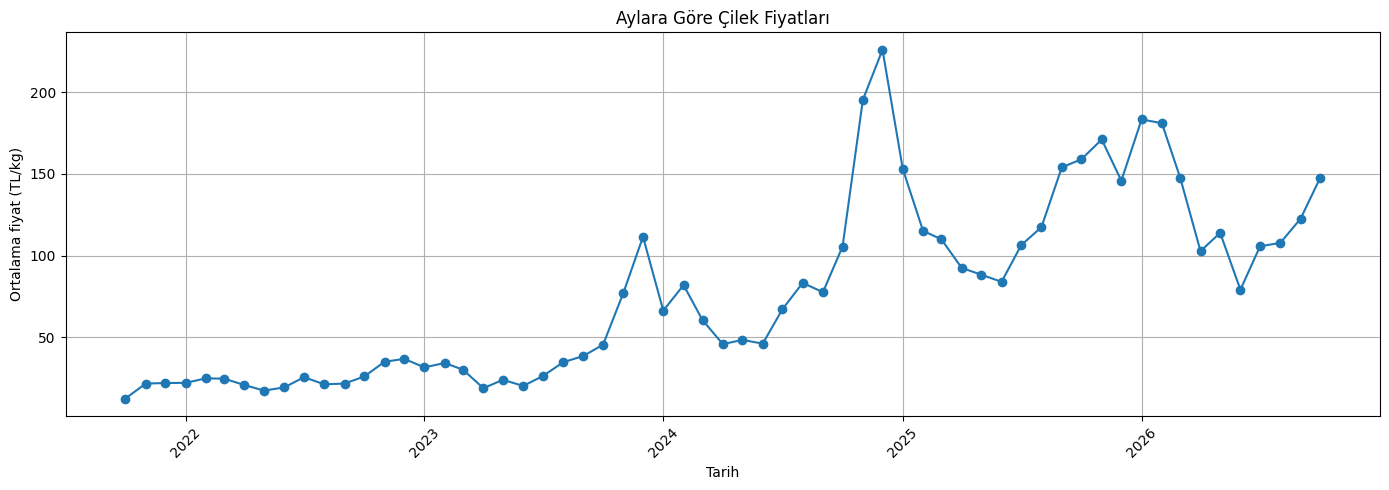

Gözlem sayısı: 61
Eksik fiyat sayısı: 0
Tarih aralığı: 2021-10-01 - 2026-10-01


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# CSV dosyasını oku
aylik_genel = pd.read_csv("/content/cilek_aylik_genel.csv")

aylik_genel["ay"] = pd.to_datetime(aylik_genel["ay"])
aylik_genel = aylik_genel.sort_values("ay").reset_index(drop=True)

# Fiyat grafiği
plt.figure(figsize=(14, 5))
plt.plot(
    aylik_genel["ay"],
    aylik_genel["aylik_fiyat"],
    marker="o"
)

plt.title("Aylara Göre Çilek Fiyatları")
plt.xlabel("Tarih")
plt.ylabel("Ortalama fiyat (TL/kg)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

print("Gözlem sayısı:", len(aylik_genel))
print("Eksik fiyat sayısı:", aylik_genel["aylik_fiyat"].isna().sum())
print("Tarih aralığı:",
      aylik_genel["ay"].min().date(),
      "-",
      aylik_genel["ay"].max().date())


In [ ]:
import pandas as pd
import numpy as np

# 1. Veriyi oku
df = pd.read_csv("/content/cilek_aylik_genel.csv")

df["ay"] = pd.to_datetime(df["ay"])
df = df.sort_values("ay").drop_duplicates(subset="ay")
df = df.set_index("ay")

# Fiyat sütununu sayısal hale getir
df["aylik_fiyat"] = pd.to_numeric(df["aylik_fiyat"], errors="coerce")

# 2. Aylar arasında eksik veri var mı kontrol et
tam_tarih_araligi = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="MS"
)

eksik_aylar = tam_tarih_araligi.difference(df.index)

print("Toplam gözlem:", len(df))
print("Eksik ay sayısı:", len(eksik_aylar))

if len(eksik_aylar) > 0:
    print("Eksik aylar:", eksik_aylar.strftime("%Y-%m").tolist())
    raise ValueError(
        "Eksik aylar bulundu. Pencereleme öncesinde bu ayları ele almamız gerekiyor."
    )

if df["aylik_fiyat"].isna().any():
    raise ValueError("Fiyat sütununda eksik değer var.")

# 3. Pencereleme: önceki 3 ay -> sonraki ay
fiyatlar = df["aylik_fiyat"].to_numpy()
tarihler = df.index

X = []
y = []
hedef_tarihleri = []

pencere_boyutu = 3

for i in range(pencere_boyutu, len(fiyatlar)):
    X.append(fiyatlar[i-pencere_boyutu:i])
    y.append(fiyatlar[i])
    hedef_tarihleri.append(tarihler[i])

X = np.array(X)
y = np.array(y)
hedef_tarihleri = pd.DatetimeIndex(hedef_tarihleri)

print("\nPencereleme tamamlandı.")
print("X boyutu:", X.shape)
print("y boyutu:", y.shape)

print("\nİlk örnek:")
print("Önceki 3 ayın fiyatları:", X[0])
print("Tahmin edilecek ay:", hedef_tarihleri[0].strftime("%Y-%m"))
print("Gerçek fiyat:", y[0])
print("SON 3 PENCERELEME ÖRNEĞİ")
print("-" * 50)

for i in range(len(X) - 3, len(X)):
    onceki_aylar = tarihler[i:i+3]
    hedef_tarih = hedef_tarihleri[i]

    print(f"\nÖrnek {i + 1}")
    print("Girdi ayları ve fiyatları:")

    for tarih, fiyat in zip(onceki_aylar, X[i]):
        print(f"  {tarih.strftime('%Y-%m')}: {fiyat:.2f} TL/kg")

    print(f"Tahmin edilecek ay: {hedef_tarih.strftime('%Y-%m')}")
    print(f"Gerçek fiyat: {y[i]:.2f} TL/kg")

Toplam gözlem: 61
Eksik ay sayısı: 0

Pencereleme tamamlandı.
X boyutu: (58, 3)
y boyutu: (58,)

İlk örnek:
Önceki 3 ayın fiyatları: [12.5        21.66666667 22.        ]
Tahmin edilecek ay: 2022-01
Gerçek fiyat: 22.11111111111111
SON 3 PENCERELEME ÖRNEĞİ
--------------------------------------------------

Örnek 56
Girdi ayları ve fiyatları:
  2026-05: 113.93 TL/kg
  2026-06: 79.12 TL/kg
  2026-07: 105.69 TL/kg
Tahmin edilecek ay: 2026-08
Gerçek fiyat: 107.79 TL/kg

Örnek 57
Girdi ayları ve fiyatları:
  2026-06: 79.12 TL/kg
  2026-07: 105.69 TL/kg
  2026-08: 107.79 TL/kg
Tahmin edilecek ay: 2026-09
Gerçek fiyat: 122.62 TL/kg

Örnek 58
Girdi ayları ve fiyatları:
  2026-07: 105.69 TL/kg
  2026-08: 107.79 TL/kg
  2026-09: 122.62 TL/kg
Tahmin edilecek ay: 2026-10
Gerçek fiyat: 147.71 TL/kg


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Veriyi kronolojik olarak eğitim ve test kümelerine ayır
bolme = int(len(X) * 0.80)

X_train = X[:bolme]
X_test = X[bolme:]

y_train = y[:bolme]
y_test = y[bolme:]

tarih_test = hedef_tarihleri[bolme:]

print("Eğitim örneği sayısı:", len(X_train))
print("Test örneği sayısı:", len(X_test))

# 2. Doğrusal regresyon modelini oluştur ve eğit
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Test verileriyle tahmin yap
y_pred = model.predict(X_test)

print("\nModel eğitildi ve tahminler oluşturuldu.")

Eğitim örneği sayısı: 46
Test örneği sayısı: 12

Model eğitildi ve tahminler oluşturuldu.


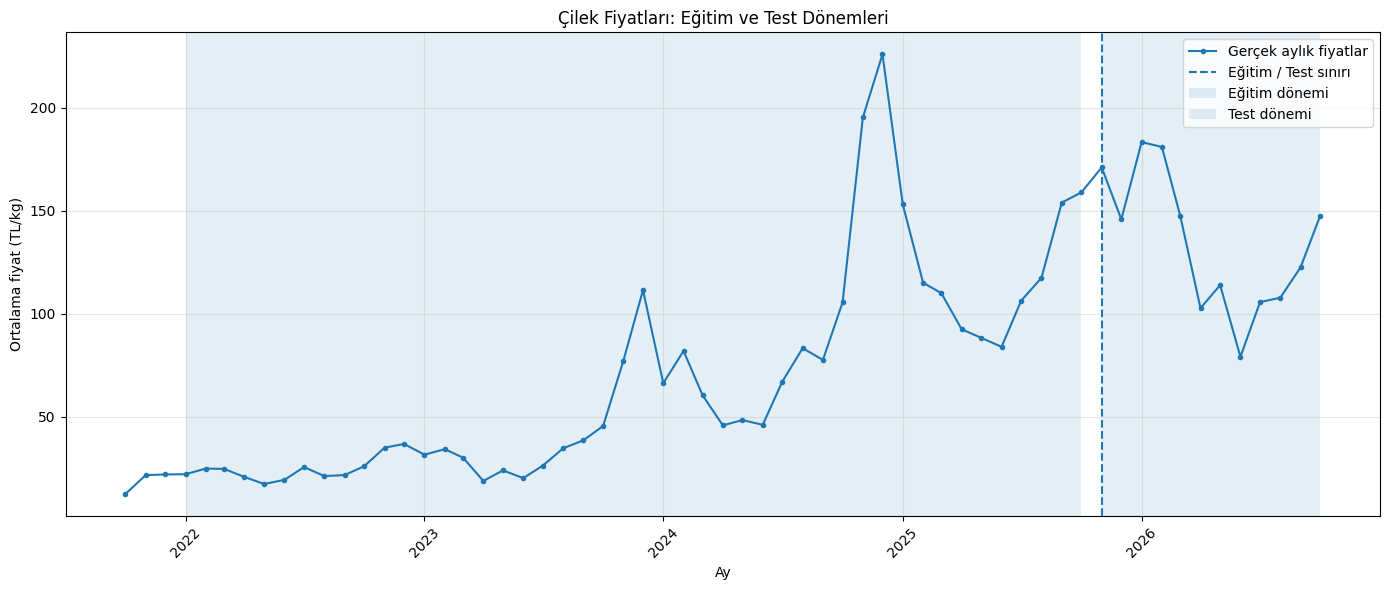

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Tüm gerçek aylık fiyatlar
plt.plot(
    df.index, df["aylik_fiyat"],
    label="Gerçek aylık fiyatlar",
    marker="o", markersize=3
)

# Eğitim-test ayrımını göster
plt.axvline(
    hedef_tarihleri[bolme],
    linestyle="--",
    label="Eğitim / Test sınırı"
)

plt.axvspan(
    hedef_tarihleri[0],
    hedef_tarihleri[bolme - 1],
    alpha=0.12,
    label="Eğitim dönemi"
)

plt.axvspan(
    hedef_tarihleri[bolme],
    hedef_tarihleri[-1],
    alpha=0.12,
    label="Test dönemi"
)

plt.title("Çilek Fiyatları: Eğitim ve Test Dönemleri")
plt.xlabel("Ay")
plt.ylabel("Ortalama fiyat (TL/kg)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


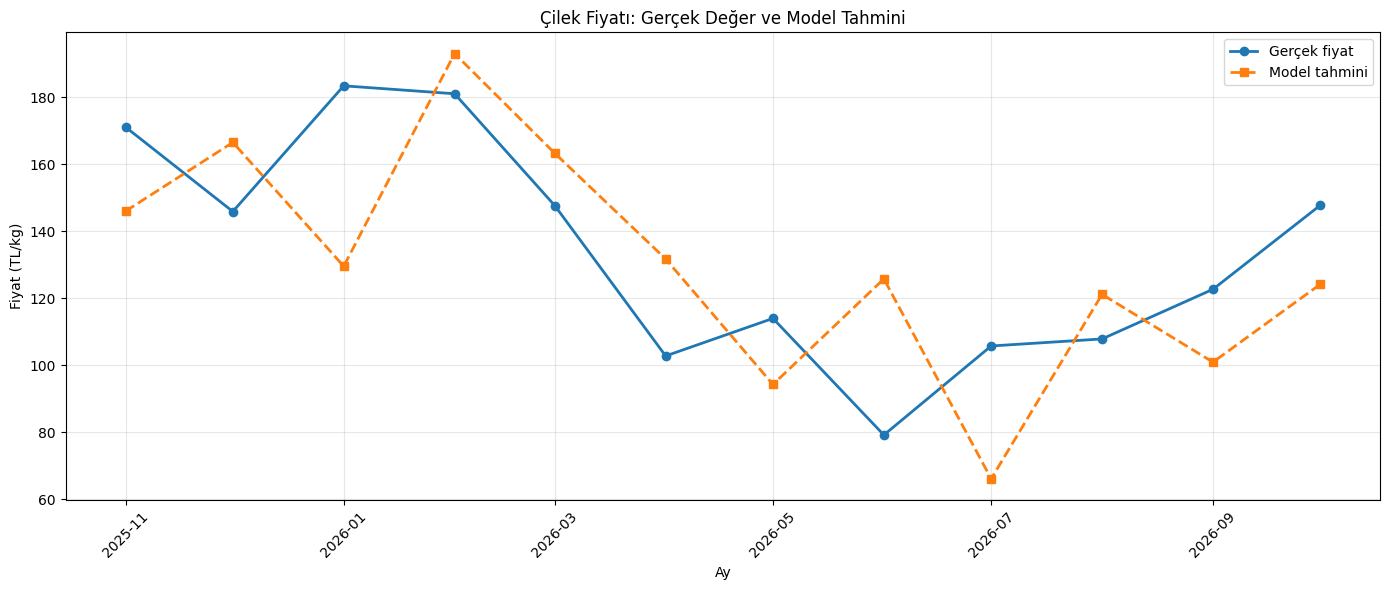

In [ ]:

plt.figure(figsize=(14, 6))

plt.plot(
    tarih_test, y_test,
    marker="o", linewidth=2,
    label="Gerçek fiyat"
)

plt.plot(
    tarih_test, y_pred,
    marker="s", linestyle="--", linewidth=2,
    label="Model tahmini"
)

plt.title("Çilek Fiyatı: Gerçek Değer ve Model Tahmini")
plt.xlabel("Ay")
plt.ylabel("Fiyat (TL/kg)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


model.coef_ = [ 0.22747568 -0.5617039   1.24058609]
model.intercept_ = 8.509290679370466

std_err = [5.63797455 0.15625923 0.23063612 0.1502711 ]

KATSAYI VE STANDART HATA TABLOSU


,Parametre,Katsayı,Standart Hata
0,Sabit terim (intercept),8.5093,5.6380
1,3 ay önceki fiyat,0.2275,0.1563
2,2 ay önceki fiyat,-0.5617,0.2306
3,1 ay önceki fiyat,1.2406,0.1503


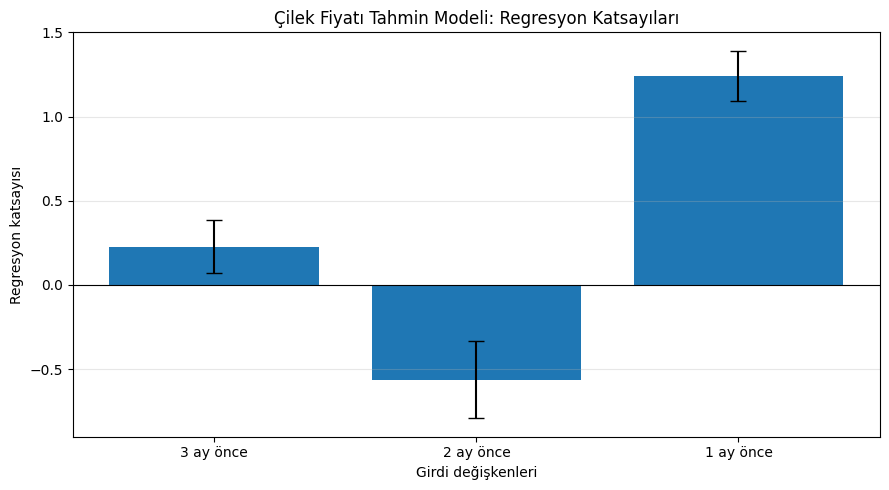

Sabit terim: 8.5093
Sabit terimin standart hatası: 5.6380


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# 1. Doğrusal regresyon katsayıları
print("model.coef_ =", model.coef_)
print("model.intercept_ =", model.intercept_)

# 2. Standart hata hesabı
X_train_stats = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_stats).fit()

std_err = ols_model.bse

print("\nstd_err =", std_err)

# 3. Katsayıları ve standart hataları tablo halinde göster
katsayi_tablosu = pd.DataFrame({
    "Parametre": [
        "Sabit terim (intercept)",
        "3 ay önceki fiyat",
        "2 ay önceki fiyat",
        "1 ay önceki fiyat"
    ],
    "Katsayı": np.r_[model.intercept_, model.coef_],
    "Standart Hata": np.asarray(std_err)
})

print("\nKATSAYI VE STANDART HATA TABLOSU")
display(katsayi_tablosu.round(4))

# 4. Regresyon katsayılarını grafikle göster
etiketler = [
    "3 ay önce",
    "2 ay önce",
    "1 ay önce"
]

katsayilar = np.asarray(model.coef_)
katsayi_standart_hatalari = np.asarray(std_err)[1:]

plt.figure(figsize=(9, 5))

plt.bar(
    etiketler,
    katsayilar,
    yerr=katsayi_standart_hatalari,
    capsize=6
)

plt.axhline(y=0, color="black", linewidth=0.8)
plt.title("Çilek Fiyatı Tahmin Modeli: Regresyon Katsayıları")
plt.xlabel("Girdi değişkenleri")
plt.ylabel("Regresyon katsayısı")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Sabit terimi ayrıca yazdır
print(f"Sabit terim: {model.intercept_:.4f}")
print(f"Sabit terimin standart hatası: {std_err[0]:.4f}")


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Başarı metrikleri
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Sonuç tablosu
metrikler = pd.DataFrame({
    "Metrik": ["R²", "MAE", "MSE", "RMSE"],
    "Sonuç": [r2, mae, mse, rmse]
})

print("DOĞRUSAL REGRESYON MODELİ BAŞARI SONUÇLARI")
display(metrikler.round(4))



DOĞRUSAL REGRESYON MODELİ BAŞARI SONUÇLARI


,Metrik,Sonuç
0,R²,0.1609
1,MAE,26.7373
2,MSE,877.2318
3,RMSE,29.6181


,Ay,Gerçek Fiyat (TL/kg),Tahmin (TL/kg),Hata,Mutlak Hata,Yüzde Hata (%)
2,2026-01,183.37,129.50,-53.87,53.87,29.38
7,2026-06,79.12,125.73,46.61,46.61,58.92
8,2026-07,105.69,66.03,-39.66,39.66,37.53
5,2026-04,102.72,131.68,28.96,28.96,28.19
0,2025-11,171.06,145.94,-25.13,25.13,14.69
11,2026-10,147.71,124.12,-23.58,23.58,15.97
10,2026-09,122.62,100.87,-21.75,21.75,17.74
1,2025-12,145.84,166.47,20.63,20.63,14.15
6,2026-05,113.93,94.20,-19.73,19.73,17.32
4,2026-03,147.61,163.24,15.62,15.62,10.58


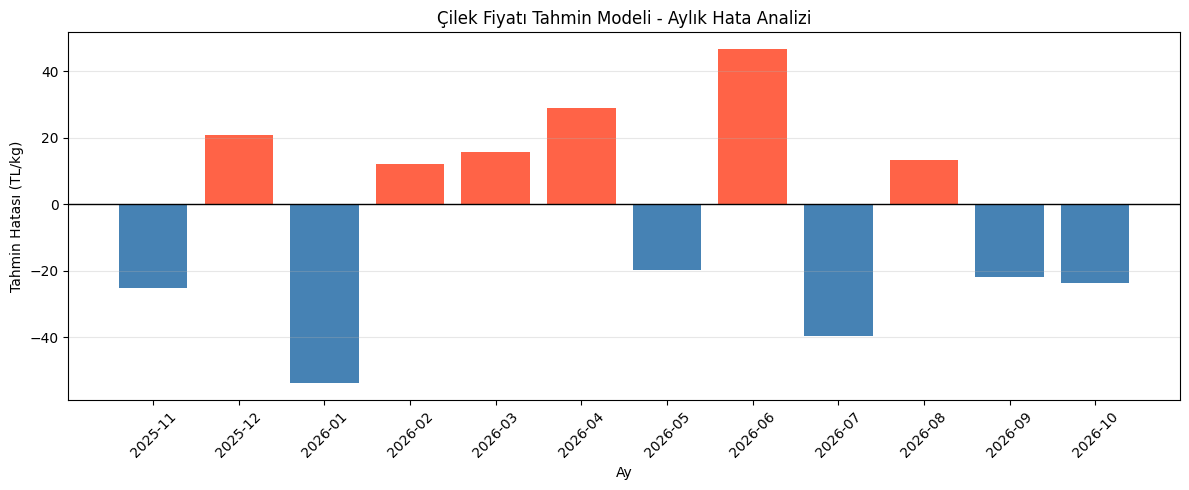

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Gerçek ve tahmin edilen fiyatları karşılaştır
hata_tablosu = pd.DataFrame({
    "Ay": tarih_test,
    "Gerçek Fiyat (TL/kg)": y_test,
    "Tahmin (TL/kg)": y_pred
})

# Hata: tahmin - gerçek
hata_tablosu["Hata"] = (
    hata_tablosu["Tahmin (TL/kg)"] -
    hata_tablosu["Gerçek Fiyat (TL/kg)"]
)

# Mutlak hata: hatanın büyüklüğü
hata_tablosu["Mutlak Hata"] = hata_tablosu["Hata"].abs()

# Yüzde hata
hata_tablosu["Yüzde Hata (%)"] = (
    hata_tablosu["Mutlak Hata"] /
    hata_tablosu["Gerçek Fiyat (TL/kg)"].abs().replace(0, np.nan)
) * 100

# Ay bilgilerini okunabilir biçime getir
hata_tablosu["Ay"] = pd.to_datetime(
    hata_tablosu["Ay"]
).dt.strftime("%Y-%m")

# En yüksek hata en üstte olacak şekilde sıralanmış tablo
display(
    hata_tablosu.sort_values(
        "Mutlak Hata", ascending=False
    ).round(2)
)

# Tarih sırasına göre sırala
grafik_verisi = hata_tablosu.copy()
grafik_verisi["Ay"] = pd.to_datetime(grafik_verisi["Ay"])
grafik_verisi = grafik_verisi.sort_values("Ay")

plt.figure(figsize=(12, 5))

plt.bar(
    grafik_verisi["Ay"].dt.strftime("%Y-%m"),
    grafik_verisi["Hata"],
    color=[
        "tomato" if hata > 0 else "steelblue"
        for hata in grafik_verisi["Hata"]
    ]
)

plt.axhline(y=0, color="black", linewidth=1)
plt.title("Çilek Fiyatı Tahmin Modeli - Aylık Hata Analizi")
plt.xlabel("Ay")
plt.ylabel("Tahmin Hatası (TL/kg)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# Verileri tarih sırasına koy
gelecek_df = df.sort_index().dropna(subset=["aylik_fiyat"])

# Son 3 aylık fiyatı al
son_uc_ay = gelecek_df["aylik_fiyat"].tail(3).to_numpy()

# Modeli tüm geçmiş verilerle yeniden eğit
fiyatlar = gelecek_df["aylik_fiyat"].to_numpy()

X_tum, y_tum = [], []

for i in range(3, len(fiyatlar)):
    X_tum.append(fiyatlar[i-3:i])
    y_tum.append(fiyatlar[i])

X_tum = np.array(X_tum)
y_tum = np.array(y_tum)

son_model = LinearRegression()
son_model.fit(X_tum, y_tum)

# Gelecek ayın fiyatını tahmin et
gelecek_tahmin = son_model.predict(
    son_uc_ay.reshape(1, -1)
)[0]

# Son tarihten sonraki ayı bul
son_tarih = gelecek_df.index[-1]
gelecek_ay = son_tarih + pd.DateOffset(months=1)

print("SON 3 AYIN FİYATLARI")
for tarih, fiyat in gelecek_df["aylik_fiyat"].tail(3).items():
    print(f"{tarih:%Y-%m}: {fiyat:.2f} TL/kg")

print("\nGELECEK AY TAHMİNİ")
print(f"Ay: {gelecek_ay:%Y-%m}")
print(f"Tahmini çilek fiyatı: {gelecek_tahmin:.2f} TL/kg")


SON 3 AYIN FİYATLARI
2026-08: 107.79 TL/kg
2026-09: 122.62 TL/kg
2026-10: 147.71 TL/kg

GELECEK AY TAHMİNİ
Ay: 2026-11
Tahmini çilek fiyatı: 146.43 TL/kg
